# Рабочая тетрадь № 4. Самостоятельные задания

Задания после примеров 1.1.3, 1.1.5, 1.2.1 и 1.3.2, плюс задание со звёздочкой, вариант 2.
Каждая ячейка с решением запускается отдельно: импорты внутри неё.
Файлы `data/Salary_Data.csv` и `data/petrol_consumption.csv` скачаны по ссылкам из тетради.


## 1. Линейные регрессионные модели


### Задание

Представьте собственные данные и постройте экстраполяцию полиномами первой, второй и третьей степени.


степень 1: y = 2.7795·x − 0.9813
  сумма квадратов остатков = 21.5278
степень 2: y = 0.2557·x^2 + 0.7335·x + 1.4056
  сумма квадратов остатков = 1.3826
степень 3: y = 0.0076·x^3 + 0.1646·x^2 + 1.0084·x + 1.2781
  сумма квадратов остатков = 1.3004
значения полиномов вне исходного отрезка:
  степень 1: y(-1) = -3.761, y(9) = 24.034
  степень 2: y(-1) = 0.928, y(9) = 28.723
  степень 3: y(-1) = 0.427, y(9) = 29.224
       x        y       p1       p2       p3
   0.000    1.210   -0.981    1.406    1.278
   1.000    2.300    1.798    2.395    2.459
   2.000    4.570    4.578    3.896    4.014
   3.000    6.120    7.357    5.908    5.990
   4.000    7.640   10.137    8.432    8.432
   5.000   11.500   12.916   11.467   11.385
   6.000   14.900   15.696   15.014   14.895
   7.000   19.490   18.475   19.072   19.008
   8.000   23.500   21.255   23.642   23.769


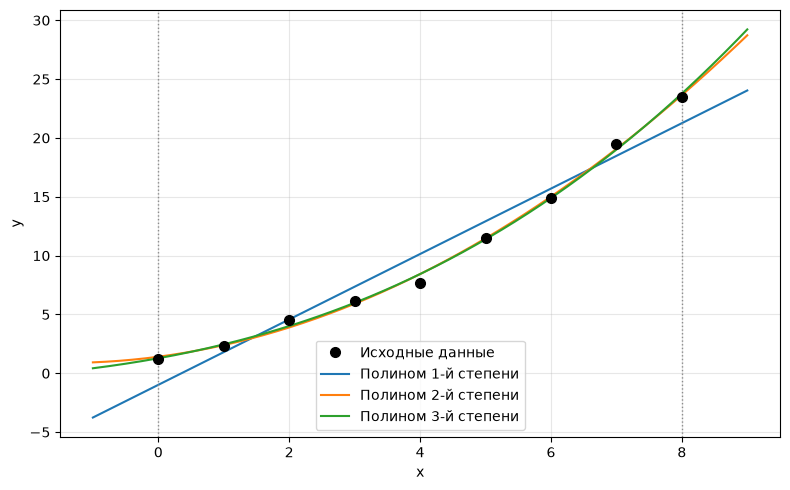

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.family"] = "DejaVu Sans"

# Девять собственных точек. К концу ряда рост быстрее, чем в начале.
x = np.arange(0, 9, dtype=float)
y = np.array([1.21, 2.30, 4.57, 6.12, 7.64, 11.50, 14.90, 19.49, 23.50])

def fit_poly(x, y, degree):
    # Столбцы матрицы плана: x^degree, ..., x, 1. Как vstack(...).T в примерах 1.1.1–1.1.3.
    columns = [x ** k for k in range(degree, -1, -1)]
    A = np.vstack(columns).T
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    return coef

def predict(coef, x_new):
    degree = len(coef) - 1
    y_hat = np.zeros_like(x_new, dtype=float)
    for i, c in enumerate(coef):
        y_hat = y_hat + c * x_new ** (degree - i)
    return y_hat

def equation(coef):
    degree = len(coef) - 1
    parts = []
    for i, c in enumerate(coef):
        power = degree - i
        number = f"{abs(c):.4f}"
        if power == 0:
            term = number
        elif power == 1:
            term = number + "·x"
        else:
            term = number + f"·x^{power}"
        if not parts:
            parts.append(("-" if c < 0 else "") + term)
        else:
            parts.append((" − " if c < 0 else " + ") + term)
    return "y = " + "".join(parts)

coefs = {}
rows = {"x": x, "y": y}
for degree in (1, 2, 3):
    coef = fit_poly(x, y, degree)
    coefs[degree] = coef
    y_hat = predict(coef, x)
    sse = float(np.sum((y - y_hat) ** 2))
    rows[f"p{degree}"] = y_hat
    print(f"степень {degree}: {equation(coef)}")
    print(f"  сумма квадратов остатков = {sse:.4f}")

# Сетка шире данных: внутри отрезка это сглаживание, снаружи — экстраполяция.
x_ext = np.linspace(-1, 9, 201)
print("значения полиномов вне исходного отрезка:")
for degree in (1, 2, 3):
    left, right = predict(coefs[degree], np.array([-1.0, 9.0]))
    print(f"  степень {degree}: y(-1) = {left:.3f}, y(9) = {right:.3f}")

table = pd.DataFrame(rows)
print(table.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y, "o", color="black", markersize=7, label="Исходные данные", zorder=3)
colors = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}
for degree in (1, 2, 3):
    ax.plot(
        x_ext,
        predict(coefs[degree], x_ext),
        color=colors[degree],
        label=f"Полином {degree}-й степени",
    )
ax.axvline(0, color="0.55", linestyle=":", linewidth=1)
ax.axvline(8, color="0.55", linestyle=":", linewidth=1)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "poly_degrees.png", dpi=140)
plt.show()


### Задание

Подставьте собственные данные и поэкспериментируйте с представленными функциями. Проанализируйте динамику изменения данных.

Функции из примеров 1.1.4 и 1.1.5:

1. \(f(x, b) = b_0 + b_1 e^{-b_2 x^2}\)
2. \(f(x, b) = b_0 + b_1 x\)
3. \(f(x, b) = b_0 + b_1 x + b_2 x^2\)
4. \(f(x, b) = b_0 + b_1 \ln x\)
5. \(f(x, b) = b_0 x^{b_1}\)


точек: 36, x от 0.40 до 4.50
y от 0.775 до 3.467
заложено: b0=0.9, b1=2.8, b2=0.55
линейное отклонение — sum(beta_cov[0]), как в примере 1.1.4
экспонента: [0.8752 2.8479 0.5397]
  сумма квадратов остатков = 0.1173, линейное отклонение = 0.000261522
прямая: [ 2.8744 -0.5757]
  сумма квадратов остатков = 6.3201, линейное отклонение = 0.0175501
парабола: [ 4.2633 -2.0808  0.3072]
  сумма квадратов остатков = 0.3749, линейное отклонение = 0.00157926
логарифм: [ 2.3559 -1.2267]
  сумма квадратов остатков = 1.7399, линейное отклонение = 0.000734933
степенная: [ 2.1746 -0.6823]
  сумма квадратов остатков = 1.3797, линейное отклонение = 0.00188072
    модель              коэффициенты  сумма квадратов  лин. откл.
экспонента    [0.8752 2.8479 0.5397]           0.1173    0.000262
    прямая         [ 2.8744 -0.5757]           6.3201    0.017550
  парабола [ 4.2633 -2.0808  0.3072]           0.3749    0.001579
  логарифм         [ 2.3559 -1.2267]           1.7399    0.000735
 степенная         [ 2

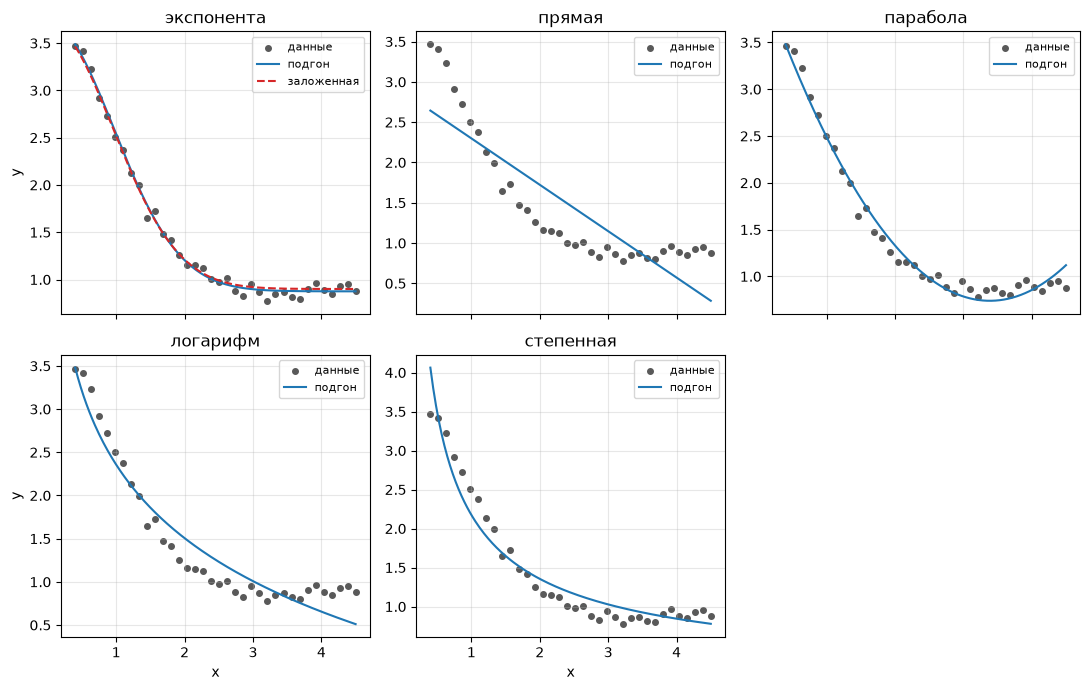

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit

plt.rcParams["font.family"] = "DejaVu Sans"

# Свои коэффициенты, не те, что в примере (0.25, 0.75, 0.5).
# Шум фиксирован seed, чтобы ячейка каждый раз давала те же точки.
beta_true = (0.9, 2.8, 0.55)
rng = np.random.default_rng(11)
x = np.linspace(0.4, 4.5, 36)
y_clean = beta_true[0] + beta_true[1] * np.exp(-beta_true[2] * x ** 2)
y = y_clean + rng.normal(0, 0.07, size=x.shape)

def f_exp(x, b0, b1, b2):
    return b0 + b1 * np.exp(-b2 * x ** 2)

def f_lin(x, b0, b1):
    return b0 + b1 * x

def f_quad(x, b0, b1, b2):
    return b0 + b1 * x + b2 * x ** 2

def f_log(x, b0, b1):
    return b0 + b1 * np.log(x)

def f_pow(x, b0, b1):
    return b0 * np.power(x, b1)

models = [
    ("экспонента", f_exp, (1.0, 1.0, 0.5)),
    ("прямая", f_lin, (1.0, -0.5)),
    ("парабола", f_quad, (2.0, -1.0, 0.1)),
    ("логарифм", f_log, (1.0, -1.0)),
    ("степенная", f_pow, (2.0, -0.5)),
]

print(f"точек: {len(x)}, x от {x[0]:.2f} до {x[-1]:.2f}")
print(f"y от {y.min():.3f} до {y.max():.3f}")
print(f"заложено: b0={beta_true[0]}, b1={beta_true[1]}, b2={beta_true[2]}")
print("линейное отклонение — sum(beta_cov[0]), как в примере 1.1.4")

fits = []
summary = []
for name, func, p0 in models:
    beta_opt, beta_cov = curve_fit(func, x, y, p0=p0, maxfev=20000)
    residuals = y - func(x, *beta_opt)
    fres = float(np.sum(residuals ** 2))
    lin_dev = float(np.sum(beta_cov[0]))
    fits.append((name, func, beta_opt))
    summary.append({
        "модель": name,
        "коэффициенты": np.array2string(beta_opt, precision=4),
        "сумма квадратов": round(fres, 4),
        "лин. откл.": float(f"{lin_dev:.6g}"),
    })
    print(f"{name}: {np.array2string(beta_opt, precision=4)}")
    print(f"  сумма квадратов остатков = {fres:.4f}, линейное отклонение = {lin_dev:.6g}")

print(pd.DataFrame(summary).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True)
axes = axes.ravel()
x_line = np.linspace(x.min(), x.max(), 200)
for ax, (name, func, beta_opt) in zip(axes, fits):
    ax.scatter(x, y, s=16, color="0.35", label="данные")
    ax.plot(x_line, func(x_line, *beta_opt), color="#1f77b4", label="подгон")
    if name == "экспонента":
        ax.plot(
            x_line,
            f_exp(x_line, *beta_true),
            color="#d62728",
            linestyle="--",
            label="заложенная",
        )
    ax.set_title(name)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[-1].axis("off")
for ax in axes[3:5]:
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[3].set_ylabel("y")
fig.tight_layout()
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "curve_fits.png", dpi=140)
plt.show()


## 2. Задачи регрессии


### Задание

Постройте модель линейной регрессии для произвольных данных из двух столбцов. Для примера можно взять точечную зависимость заработной платы от опыта работы (Salary_Data.csv по ссылке из тетради). Найдите коэффициенты линии регрессии. Постройте прогноз.


   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
shape: (30, 2)
       YearsExperience     Salary
count            30.00      30.00
mean              5.31   76003.00
std               2.84   27414.43
min               1.10   37731.00
25%               3.20   56720.75
50%               4.70   65237.00
75%               7.70  100544.75
max              10.50  122391.00
свободный член = 26780.10
наклон = 9312.58
уравнение: зарплата = 26780.10 + 9312.58 · стаж
 Стаж     Факт   Прогноз
  1.5  37731.0  40748.96
  3.9  63218.0  63099.14
  4.1  57081.0  64961.66
  8.7 109431.0 107799.50
  9.5 116969.0 115249.56
 10.3 122391.0 122699.62
MSE на тесте = 12823412.3
RMSE на тесте = 3581.0
прогноз при стаже 6.5 лет: 87312


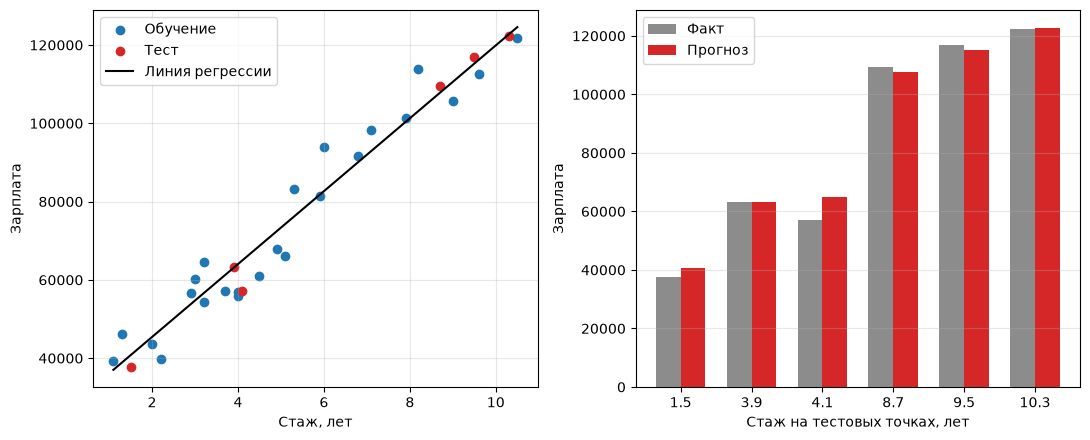

In [3]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

plt.rcParams["font.family"] = "DejaVu Sans"

def find_data():
    here = Path.cwd()
    for folder in (here / "data", here / "homework_4" / "data"):
        if (folder / "Salary_Data.csv").exists():
            return folder
    raise FileNotFoundError("Нет data/Salary_Data.csv рядом с ноутбуком")

data_dir = find_data()
dataset = pd.read_csv(data_dir / "Salary_Data.csv")
print(dataset.head())
print("shape:", dataset.shape)
print(dataset.describe().round(2))

X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, 1].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
regressor = LinearRegression()
regressor.fit(X_train, y_train)

slope = float(regressor.coef_[0])
intercept = float(regressor.intercept_)
print(f"свободный член = {intercept:.2f}")
print(f"наклон = {slope:.2f}")
print(f"уравнение: зарплата = {intercept:.2f} + {slope:.2f} · стаж")

y_pred = regressor.predict(X_test)
compare = pd.DataFrame({"Стаж": X_test.ravel(), "Факт": y_test, "Прогноз": y_pred})
compare = compare.sort_values("Стаж")
print(compare.round(2).to_string(index=False))
mse = metrics.mean_squared_error(y_test, y_pred)
print(f"MSE на тесте = {mse:.1f}")
print(f"RMSE на тесте = {np.sqrt(mse):.1f}")

# Прогноз в точке, которой нет в таблице.
years_new = np.array([[6.5]])
salary_new = float(regressor.predict(years_new)[0])
print(f"прогноз при стаже 6.5 лет: {salary_new:.0f}")

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = regressor.predict(x_line)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_train, y_train, color="#1f77b4", label="Обучение")
axes[0].scatter(X_test, y_test, color="#d62728", label="Тест")
axes[0].plot(x_line, y_line, color="black", label="Линия регрессии")
axes[0].set_xlabel("Стаж, лет")
axes[0].set_ylabel("Зарплата")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

bar = compare.reset_index(drop=True)
idx = np.arange(len(bar))
width = 0.35
axes[1].bar(idx - width / 2, bar["Факт"], width, label="Факт", color="0.55")
axes[1].bar(idx + width / 2, bar["Прогноз"], width, label="Прогноз", color="#d62728")
axes[1].set_xticks(idx)
axes[1].set_xticklabels([f"{v:.1f}" for v in bar["Стаж"]])
axes[1].set_xlabel("Стаж на тестовых точках, лет")
axes[1].set_ylabel("Зарплата")
axes[1].legend()
axes[1].grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "salary.png", dpi=140)
plt.show()


## 3. Множественная регрессия


### Задание

Постройте модель множественной линейной регрессии для произвольных данных из нескольких столбцов. Для примера можно взять потребление газа (в миллионах галлонов) в 48 штатах США. Найдите коэффициенты множественной регрессии. Постройте прогноз.

Берётся `petrol_consumption.csv` по ссылке из тетради.


   Petrol_tax  Average_income  Paved_Highways  Driver_licence  \
0         9.0            3571            1976           0.525   
1         9.0            4092            1250           0.572   
2         9.0            3865            1586           0.580   
3         7.5            4870            2351           0.529   
4         8.0            4399             431           0.544   

   Petrol_Consumption  
0                 541  
1                 524  
2                 561  
3                 414  
4                 410  
shape: (48, 5)
       Petrol_tax  Average_income  Paved_Highways  Driver_licence  \
count      48.000          48.000          48.000          48.000   
mean        7.668        4241.833        5565.417           0.570   
std         0.951         573.624        3491.507           0.055   
min         5.000        3063.000         431.000           0.451   
25%         7.000        3739.000        3110.250           0.530   
50%         7.500        4298.000   

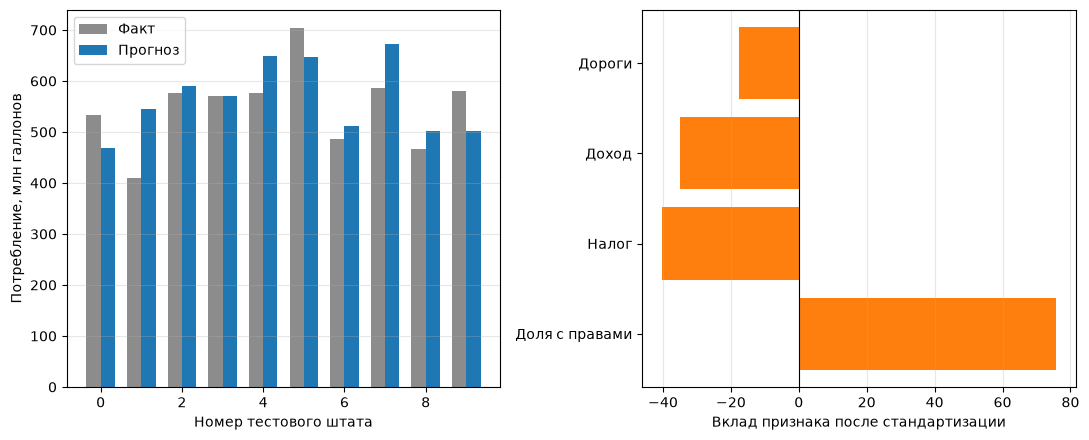

In [4]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

plt.rcParams["font.family"] = "DejaVu Sans"

def find_data():
    here = Path.cwd()
    for folder in (here / "data", here / "homework_4" / "data"):
        if (folder / "petrol_consumption.csv").exists():
            return folder
    raise FileNotFoundError("Нет data/petrol_consumption.csv рядом с ноутбуком")

data_dir = find_data()
dataset = pd.read_csv(data_dir / "petrol_consumption.csv")
dataset = dataset.rename(columns={"Population_Driver_licence(%)": "Driver_licence"})
features = ["Petrol_tax", "Average_income", "Paved_Highways", "Driver_licence"]
print(dataset.head())
print("shape:", dataset.shape)
print(dataset.describe().round(3))

X = dataset[features]
y = dataset["Petrol_Consumption"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

regressor = LinearRegression()
regressor.fit(X_train, y_train)
coef = pd.DataFrame(
    {"коэффициент": regressor.coef_},
    index=features,
)
print(f"свободный член = {regressor.intercept_:.4f}")
print(coef.round(6))

# Коэффициенты в разных единицах. После стандартизации X их можно сравнивать между собой.
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
reg_s = LinearRegression().fit(X_train_s, y_train)
coef_s = pd.Series(reg_s.coef_, index=features).sort_values(key=np.abs, ascending=False)
print("коэффициенты при стандартизованных признаках:")
print(coef_s.round(3).to_string())

y_pred = regressor.predict(X_test)
compare = pd.DataFrame({
    "Факт": y_test.to_numpy(),
    "Прогноз": y_pred,
})
compare["ошибка"] = compare["Факт"] - compare["Прогноз"]
print(compare.round(1).to_string(index=True))
mse = metrics.mean_squared_error(y_test, y_pred)
print(f"MSE на тесте = {mse:.2f}")
print(f"RMSE на тесте = {np.sqrt(mse):.2f}")

# Прогноз для новых значений: налог 8, доход 4000, дороги 3000, доля прав 0.55.
new_row = pd.DataFrame(
    [[8.0, 4000.0, 3000.0, 0.55]],
    columns=features,
)
new_pred = float(regressor.predict(new_row)[0])
print(f"прогноз для (налог=8, доход=4000, дороги=3000, права=0.55): {new_pred:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
idx = np.arange(len(compare))
width = 0.35
axes[0].bar(idx - width / 2, compare["Факт"], width, label="Факт", color="0.55")
axes[0].bar(idx + width / 2, compare["Прогноз"], width, label="Прогноз", color="#1f77b4")
axes[0].set_xlabel("Номер тестового штата")
axes[0].set_ylabel("Потребление, млн галлонов")
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)

names = {
    "Driver_licence": "Доля с правами",
    "Petrol_tax": "Налог",
    "Average_income": "Доход",
    "Paved_Highways": "Дороги",
}
order = coef_s.index.tolist()
axes[1].barh([names[k] for k in order], coef_s.loc[order], color="#ff7f0e")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Вклад признака после стандартизации")
axes[1].grid(True, axis="x", alpha=0.3)
fig.tight_layout()
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "petrol.png", dpi=140)
plt.show()


## 4. Задание*

Экспериментально получены N значений величины Y при различных значениях величины X. Построить полиномы первой и второй степени, аппроксимирующие результаты эксперимента, с применением метода наименьших квадратов. Результаты выводятся в виде таблиц значений и графиков, полученных полиномов.

Вариант 2.

| x | y |
|---|---|
| 0,0 | 5,0 |
| 0,2 | 5,0 |
| 0,4 | 4,0 |
| 0,6 | 4,0 |
| 0,8 | 6,0 |
| 1,0 | 6,0 |


степень 1: y = 1.1429·x + 4.4286
степень 2: y = 5.3571·x^2 − 4.2143·x + 5.1429
сумма квадратов, степень 1: 3.0857
сумма квадратов, степень 2: 1.3714
       x        y  полином 1  остаток 1  полином 2  остаток 2
  0.0000   5.0000     4.4286     0.5714     5.1429    -0.1429
  0.2000   5.0000     4.6571     0.3429     4.5143     0.4857
  0.4000   4.0000     4.8857    -0.8857     4.3143    -0.3143
  0.6000   4.0000     5.1143    -1.1143     4.5429    -0.5429
  0.8000   6.0000     5.3429     0.6571     5.2000     0.8000
  1.0000   6.0000     5.5714     0.4286     6.2857    -0.2857


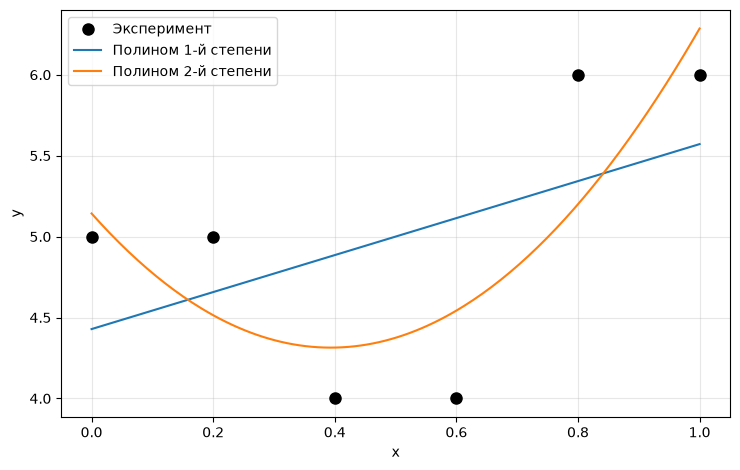

In [5]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.family"] = "DejaVu Sans"

x = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
y = np.array([5.0, 5.0, 4.0, 4.0, 6.0, 6.0])

def fit_poly(x, y, degree):
    columns = [x ** k for k in range(degree, -1, -1)]
    A = np.vstack(columns).T
    return np.linalg.lstsq(A, y, rcond=None)[0]

def predict(coef, x_new):
    degree = len(coef) - 1
    y_hat = np.zeros_like(x_new, dtype=float)
    for i, c in enumerate(coef):
        y_hat = y_hat + c * x_new ** (degree - i)
    return y_hat

def equation(coef):
    degree = len(coef) - 1
    parts = []
    for i, c in enumerate(coef):
        power = degree - i
        number = f"{abs(c):.4f}"
        if power == 0:
            term = number
        elif power == 1:
            term = number + "·x"
        else:
            term = number + f"·x^{power}"
        if not parts:
            parts.append(("-" if c < 0 else "") + term)
        else:
            parts.append((" − " if c < 0 else " + ") + term)
    return "y = " + "".join(parts)

coef1 = fit_poly(x, y, 1)
coef2 = fit_poly(x, y, 2)
y1 = predict(coef1, x)
y2 = predict(coef2, x)

print("степень 1:", equation(coef1))
print("степень 2:", equation(coef2))
print(f"сумма квадратов, степень 1: {np.sum((y - y1) ** 2):.4f}")
print(f"сумма квадратов, степень 2: {np.sum((y - y2) ** 2):.4f}")

table = pd.DataFrame({
    "x": x,
    "y": y,
    "полином 1": y1,
    "остаток 1": y - y1,
    "полином 2": y2,
    "остаток 2": y - y2,
})
print(table.to_string(index=False, float_format=lambda v: f"{v:8.4f}"))

x_line = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(x, y, "o", color="black", markersize=8, label="Эксперимент", zorder=3)
ax.plot(x_line, predict(coef1, x_line), color="#1f77b4", label="Полином 1-й степени")
ax.plot(x_line, predict(coef2, x_line), color="#ff7f0e", label="Полином 2-й степени")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / "variant2.png", dpi=140)
plt.show()
